# GPTQ-2D

GPTQ-2D rounds a matrix $X\in\mathbb{R}^{m\times n}$ under the two-sided objective
$$
\left\|A\left(Z-X\right)B\right\|_{\mathrm{F}}^2=\operatorname{tr}\left(\left(Z-X\right)^{\top}G\left(Z-X\right)H\right),
$$
with nonsingular $A\in\mathbb{R}^{m\times m}$ and $B\in\mathbb{R}^{n\times n}$ and the Gram matrices $G=A^{\top}A$ and $H=BB^{\top}$.
For a layer of an LLM, $G$ and $H$ are the two Kronecker factors of its Hessian, as in YAQA.
The objective is a quadratic form in $\operatorname{vec}\left(Z-X\right)$.
One-dimensional adaptive rounding, as in GPTQ, can thus round $\operatorname{vec}\left(X\right)$, with $mn$ coordinates and $O\left(m^2n^2\right)$ work.
GPTQ-2D reproduces that sweep in exact arithmetic, in $m+n-1$ stages and $O\left(mn\left(m+n\right)\right)$ work.

This notebook has four parts.
1. A quick start on a synthetic layer.
2. A check that the algorithms of the paper and the implementations here all give the same rounding.
3. The time of one sweep as the matrix grows.
4. Super-entries, which let any quantizer round groups of entries jointly.

It needs PyTorch, Triton and Matplotlib, and it imports the four modules next to it.
The Triton kernels need a CUDA GPU.
Without one, the notebook runs the PyTorch implementations on smaller matrices, and Section 3 times only those.

In [1]:
import functools
import statistics
import time

import matplotlib.pyplot as plt
import torch
import triton

from gptq_2d import (
    capture_gptq_2d, direct_2d, direct_2d_super_entry, gptq_2d, gptq_2d_super_entry, gptq_2d_super_entry_torch, gptq_2d_torch,
)
from gptq_2d_reference import (
    alg1, alg2, alg2_d_sided, alg3, alg3_super_entry, alg4, alg5, alg6, alg7, ldl, ldl_of_inverse, yaqa_iterative,
)
from quantizer_int import (
    affine_quantizer_torch, affine_quantizer_triton, int_abs_max_quantizer_torch, int_abs_max_quantizer_triton,
)
from quantizer_trellis import hyb, trellis_quantizer_super_entry_torch, trellis_quantizer_super_entry_triton

%config InlineBackend.figure_format = "retina"
cuda = torch.cuda.is_available()
device = torch.device("cuda" if cuda else "cpu")
# One sweep of GPTQ-2D. The Triton kernels need a GPU, and the PyTorch versions take the same inputs.
sweep = gptq_2d if cuda else gptq_2d_torch
sweep_super_entry = gptq_2d_super_entry if cuda else gptq_2d_super_entry_torch
torch.manual_seed(0)
threads = torch.get_num_threads()
hardware = torch.cuda.get_device_name(device) if cuda else f"CPU with {threads} thread{'' if threads == 1 else 's'}"
print(f"{hardware}, PyTorch {torch.__version__}, Triton {triton.__version__}")

NVIDIA RTX A6000, PyTorch 2.12.1+cu132, Triton 3.7.1


Three helpers build a synthetic Gram matrix, evaluate the objective and time a function.
The Gram matrices are normalized and damped as YAQA does with its Hessians.

In [2]:
def gram(n, dtype=torch.float32):
    """A synthetic n x n Gram matrix with random eigenvectors and eigenvalues 1/k for k = 1, ..., n,
    scaled to a unit mean diagonal and damped by 0.01."""
    Q, _ = torch.linalg.qr(torch.randn(n, n, dtype=dtype, device=device))
    G = (Q / torch.arange(1, n + 1, dtype=dtype, device=device)) @ Q.T
    G /= G.diagonal().mean()
    G.diagonal().add_(0.01)
    return G


def objective(Z, X, G, H):
    """The two-sided objective tr((Z - X)^T G (Z - X) H)."""
    R = Z - X
    return ((G @ R) * (R @ H)).sum().item()


def time_ms(fn, reps=3):
    """The median time of fn() in milliseconds over reps calls, after one warm-up call."""
    times = []
    for _ in range(1 + reps):
        torch.get_device_module(device).synchronize()  # a no-op on the CPU
        start = time.perf_counter()
        fn()
        torch.get_device_module(device).synchronize()
        times.append(1e3 * (time.perf_counter() - start))
    return statistics.median(times[1:])

## 1. Quick start

`gptq_2d(X, L, U)` takes the feedback factors from the LDL decompositions
$$
L\Lambda_L L^{\top}=G^{-1},\qquad U^{\top}\Lambda_U U=H^{-1},
$$
with unit lower triangular $L\in\mathbb{R}^{m\times m}$, unit upper triangular $U\in\mathbb{R}^{n\times n}$ and diagonal $\Lambda_L$ and $\Lambda_U$.
`ldl_of_inverse` computes them without forming $G^{-1}$ or $H^{-1}$.
The default quantizer rounds to the nearest integer, so $X$ is measured in quantization steps.
`gptq_2d_torch` takes the same inputs and also runs without a GPU.
The notebook calls `sweep`, which is `gptq_2d` on a GPU and `gptq_2d_torch` otherwise.

GPTQ is the special case $L=I$, which ignores $G$.
Round to nearest (RTN) ignores both Gram matrices.
`capture_gptq_2d` records the whole sweep once as a CUDA graph and replays it on new inputs of the same shapes, without Python.

In [3]:
m, n = (4096, 4096) if cuda else (1024, 1024)
G, H = gram(m), gram(n)
X = 4 * torch.randn(m, n, device=device)

L = ldl_of_inverse(G)    # L Lambda_L L^T = G^{-1}
U = ldl_of_inverse(H).T  # U^T Lambda_U U = H^{-1}
Z = sweep(X, L, U)       # the first call of gptq_2d compiles the Triton kernels

Z_gptq = sweep(X, torch.eye(m, device=device), U)
Z_rtn = X.round()
rtn = objective(Z_rtn, X, G, H)
print("objective relative to RTN")
for name, Z_method in ("RTN", Z_rtn), ("GPTQ (L = I)", Z_gptq), ("GPTQ-2D", Z):
    print(f"{name:<13} {100 * objective(Z_method, X, G, H) / rtn:5.1f}%")

print(f"{sweep.__name__} rounds this {m} x {n} matrix in {time_ms(lambda: sweep(X, L, U)):.0f} ms.")
if cuda:
    replay = capture_gptq_2d(X, L, U)
    print(f"Replayed as a CUDA graph, it takes {time_ms(lambda: replay(X, L, U)):.0f} ms.")

objective relative to RTN
RTN           100.0%
GPTQ (L = I)   32.3%
GPTQ-2D        10.6%
gptq_2d rounds this 4096 x 4096 matrix in 563 ms.
Replayed as a CUDA graph, it takes 53 ms.


## 2. All algorithms give the same rounding

`gptq_2d_reference.py` follows Algorithms 1-7 of the paper line by line.
Theorem 1 of the paper states that GPTQ-2D (Algorithm 3) returns the same rounded matrix as Algorithm 1 on $x=\operatorname{vec}\left(X\right)$, with the feedback $F=U^{\top}\otimes L$.
We check this on a small FP64 instance, for Algorithms 2-7, and for the implementations `direct_2d`, `gptq_2d_torch` and `gptq_2d`.

Algorithm 1 takes $F$ from the LDL decomposition of $\left(H\otimes G\right)^{-1}$, computed directly from the Kronecker Gram matrix.
It equals $U^{\top}\otimes L$ up to rounding.
Algorithm 4 rounds a $D$-dimensional tensor with one unit lower triangular factor per mode.
For $D=2$, these factors are $L$ and $U^{\top}$.
`alg2_d_sided` applies Algorithm 2's dense updates to such a tensor.

Each entry has its own codebook here, with codes $-3,\ldots,2$ times a scale that depends on its position.
An entry rounded at a wrong position, or a feedback term lost, would then likely change the rounded matrix.

In [4]:
m, n = 24, 40
dtype = torch.float64
G, H = gram(m, dtype), gram(n, dtype)
X = 4 * torch.randn(m, n, dtype=dtype, device=device)
L, U = ldl_of_inverse(G), ldl_of_inverse(H).T

i, j = torch.arange(m, device=device)[:, None], torch.arange(n, device=device)
S = ((i + 2 * j) % 3 - 1).to(dtype).exp2()  # the scale of each entry: 1/2, 1 or 2


def Q(y, i, j):
    """The reference algorithms' quantizer: codes -3, ..., 2 times the scale of entry (i, j)."""
    return (y / S[i, j]).round().clamp(-3, 2) * S[i, j]


F = ldl_of_inverse(torch.kron(H, G))  # F Lambda_F F^T = (H (x) G)^{-1}
print(f"max |F - U^T (x) L| = {(F - torch.kron(U.T, L)).abs().max():.1e}")
x = X.T.flatten()  # vec(X): entry (i, j) is coordinate k = j m + i
Z_ref = alg1(x, F, Q=lambda y, k: Q(y, k % m, k // m)).reshape(n, m).T

max |F - U^T (x) L| = 7.9e-15


The implementations in `gptq_2d.py` call the quantizer once per stage.
It receives the live matrix $Y$ flattened to `[..., m*n]`, a slice that selects the entries of the stage, the tensors in `quantizer_inputs`, and the output tensor `out`.
The earlier stages of $Y$ already hold their rounded values.
`affine_quantizer_torch` reads each entry's scale with the same slice.
On a GPU, the last two rows use `affine_quantizer_triton`, the same quantizer in Triton.
`gptq_2d` runs the blocked Algorithm 5 with two levels of blocks, of 32 and 512 stages by default.
The small blocks below make both levels flush on this small matrix.
Without a GPU, the cell skips `gptq_2d` and `capture_gptq_2d`.

In [5]:
quantizer = functools.partial(affine_quantizer_torch, qmin=-3, qmax=2)
options = dict(quantizer=quantizer, quantizer_inputs=(S, torch.zeros_like(S)))  # scales and zero points
runs = {
    "Algorithm 2, alg2": lambda: alg2(X, L, U, Q=Q),
    "Algorithm 2, alg2_d_sided with D = 2": lambda: alg2_d_sided(X, [L, U.T], Q=Q),
    "Algorithm 3, alg3": lambda: alg3(X, L, U, Q=Q),
    "Algorithm 4, alg4 with D = 2": lambda: alg4(X, [L, U.T], Q=Q),
    "Algorithm 5, alg5 with w = (2, 4)": lambda: alg5(X, L, U, w=(2, 4), Q=Q),
    "Algorithm 5, alg5 with w = (3, 5, 16)": lambda: alg5(X, L, U, w=(3, 5, 16), Q=Q),
    "Algorithm 6, alg6": lambda: alg6(X, L, U, Q=Q),
    "Algorithm 7, alg7": lambda: alg7(X, L, U, Q=Q),
    "direct_2d (Algorithm 2)": lambda: direct_2d(X, L, U, **options),
    "gptq_2d_torch (Algorithm 3)": lambda: gptq_2d_torch(X, L, U, **options),
}
if cuda:  # the Triton kernels, with small blocks
    blocks = dict(inner_block_size=4, outer_block_size=16)
    runs["gptq_2d (Algorithm 5)"] = lambda: gptq_2d(X, L, U, **blocks, **options)
    runs["capture_gptq_2d (CUDA graph)"] = lambda: capture_gptq_2d(X, L, U, **blocks, **options)(X, L, U, S, torch.zeros_like(S))
    triton_options = dict(options, quantizer=functools.partial(affine_quantizer_triton, qmin=-3, qmax=2))
    runs["gptq_2d, Triton quantizer"] = lambda: gptq_2d(X, L, U, **blocks, **triton_options)
    runs["capture_gptq_2d, Triton quantizer"] = lambda: capture_gptq_2d(X, L, U, **blocks, **triton_options)(X, L, U, S, torch.zeros_like(S))
for name, run in runs.items():
    print(f"{name:<38} {'matches' if run().equal(Z_ref) else 'differs from'} Algorithm 1")

Algorithm 2, alg2                      matches Algorithm 1
Algorithm 2, alg2_d_sided with D = 2   matches Algorithm 1
Algorithm 3, alg3                      matches Algorithm 1
Algorithm 4, alg4 with D = 2           matches Algorithm 1
Algorithm 5, alg5 with w = (2, 4)      matches Algorithm 1
Algorithm 5, alg5 with w = (3, 5, 16)  matches Algorithm 1
Algorithm 6, alg6                      matches Algorithm 1
Algorithm 7, alg7                      matches Algorithm 1
direct_2d (Algorithm 2)                matches Algorithm 1
gptq_2d_torch (Algorithm 3)            matches Algorithm 1
gptq_2d (Algorithm 5)                  matches Algorithm 1
capture_gptq_2d (CUDA graph)           matches Algorithm 1
gptq_2d, Triton quantizer              matches Algorithm 1
capture_gptq_2d, Triton quantizer      matches Algorithm 1


### The same rounding as YAQA

YAQA rounds $p\times q$ super-entries jointly, one anti-diagonal at a time from the bottom-right corner.
`yaqa_iterative` follows the YAQA_iterative listing of its paper term by term.
It factors the Gram matrices themselves, not their inverses.
GPTQ-2D sweeps from the top-left corner, so we rotate the problem by 180 degrees.
The quantizer gives each row of a super-entry its own scale, from its current absolute maximum.
It rounds a rotated super-entry to the rotated result, so the rotated sweep can use it unchanged.

In [6]:
p, q = 4, 8
joint = functools.partial(int_abs_max_quantizer_torch, qmin=-2, qmax=1, dtype=torch.bfloat16)  # 2-bit codes, BF16 scales


def Q_joint(y, i, j):
    """The reference algorithms' quantizer for super-entries y of shape (|I_s|, p, q)."""
    out = torch.empty_like(y)
    joint(y, lambda t: t, out=out)
    return out


Lin = ldl(H, size=q) - torch.eye(n, dtype=dtype, device=device)  # YAQA's factors, with zero diagonal blocks
Lout = ldl(G, size=p) - torch.eye(m, dtype=dtype, device=device)
Z_yaqa = yaqa_iterative(X, Lin, Lout, p, q, Q=Q_joint)

X_r, G_r, H_r = X.flip(0, 1), G.flip(0, 1), H.flip(0, 1)  # the rotated problem
L_r, U_r = ldl_of_inverse(G_r, size=p), ldl_of_inverse(H_r, size=q).T  # identity diagonal blocks
Z_alg3 = alg3_super_entry(X_r, L_r, U_r, Q=Q_joint, super_entry_shape=(p, q)).flip(0, 1)
Z_direct = direct_2d_super_entry(X_r, L_r, U_r, quantizer=joint, super_entry_shape=(p, q)).flip(0, 1)
Z_sweep = sweep_super_entry(X_r, L_r, U_r, quantizer=joint, super_entry_shape=(p, q)).flip(0, 1)
for name, Z_method in (
    ("alg3_super_entry", Z_alg3), ("direct_2d_super_entry", Z_direct), (sweep_super_entry.__name__, Z_sweep),
):
    print(f"{name:<26} {'matches' if Z_method.equal(Z_yaqa) else 'differs from'} yaqa_iterative")

alg3_super_entry           matches yaqa_iterative
direct_2d_super_entry      matches yaqa_iterative
gptq_2d_super_entry        matches yaqa_iterative


These matches hold in FP64 on these instances.
`python test_gptq_2d.py` runs more such checks, with batches, in-place runs and CUDA graphs.
`python gptq_2d_reference.py` also checks super-entries and Algorithm 4 in one to four dimensions against Algorithm 1.

## 3. Speed

Algorithm 2 updates the rest of the matrix for every entry, with $O\left(m^2n^2\right)$ work.
GPTQ-2D needs $O\left(mn\left(m+n\right)\right)$.
`gptq_2d_torch` runs Algorithm 3 with a few PyTorch operations per stage.
Each update reads and writes up to a whole row or column, with only a few operations per entry, so memory bandwidth limits it.
`gptq_2d` defers most of the feedback into dense matrix products in Triton kernels (Algorithm 5).
Both launch their kernels from Python for each of the $m+n-1$ stages, and the CUDA graph of `capture_gptq_2d` runs without Python.
Without a GPU, this section times only the two PyTorch versions, on smaller matrices.

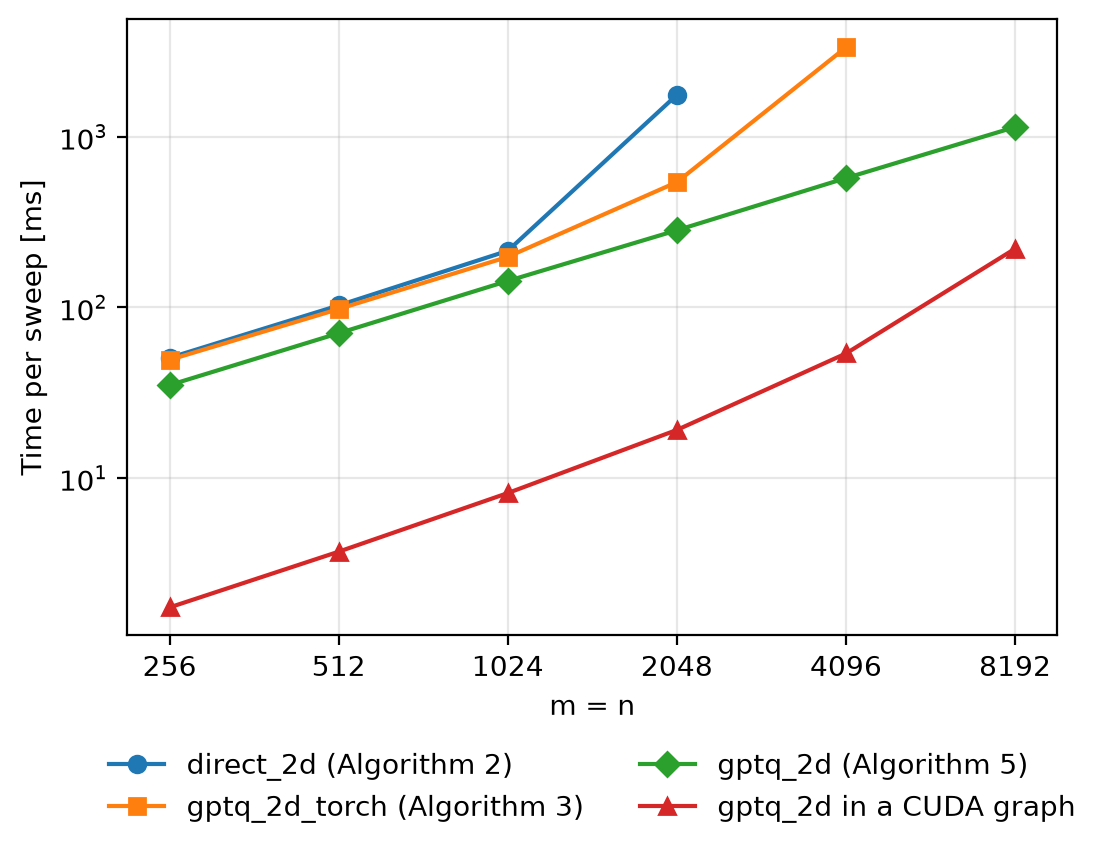

time per sweep [ms]              256     512    1024    2048    4096    8192
direct_2d (Algorithm 2)         50.6   102.6   214.3  1755.9       -       -
gptq_2d_torch (Algorithm 3)     49.2    97.7   197.5   541.1  3332.0       -
gptq_2d (Algorithm 5)           35.0    70.5   142.7   282.7   571.5  1137.1
gptq_2d in a CUDA graph          1.7     3.7     8.2    19.1    53.6   220.5


In [7]:
if cuda:
    sizes = [256, 512, 1024, 2048, 4096, 8192]
    methods = {  # the largest size to time
        "direct_2d (Algorithm 2)": (direct_2d, 2048),
        "gptq_2d_torch (Algorithm 3)": (gptq_2d_torch, 4096),
        "gptq_2d (Algorithm 5)": (gptq_2d, 8192),
        "gptq_2d in a CUDA graph": (None, 8192),
    }
else:  # only the PyTorch versions, on smaller matrices
    sizes = [64, 128, 256, 512, 1024]
    methods = {
        "direct_2d (Algorithm 2)": (direct_2d, 512),
        "gptq_2d_torch (Algorithm 3)": (gptq_2d_torch, 1024),
    }
times = {name: {} for name in methods}
for n in sizes:
    X = 4 * torch.randn(n, n, device=device)
    L, U = ldl_of_inverse(gram(n)), ldl_of_inverse(gram(n)).T
    for name, (run, largest) in methods.items():
        if n <= largest:
            if run is None:
                replay = capture_gptq_2d(X, L, U)
                times[name][n] = time_ms(lambda: replay(X, L, U))
            else:
                times[name][n] = time_ms(lambda: run(X, L, U))

fig, ax = plt.subplots(figsize=(6, 4))
for (name, by_size), marker in zip(times.items(), "osD^"):
    ax.plot(list(by_size), list(by_size.values()), marker=marker, label=name)
ax.set(xscale="log", yscale="log", xlabel="m = n", ylabel="Time per sweep [ms]")
ax.set_xticks(sizes, [str(k) for k in sizes])
ax.minorticks_off()
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.show()

print(f"{'time per sweep [ms]':<28}" + "".join(f"{k:>8}" for k in sizes))
for name, by_size in times.items():
    print(f"{name:<28}" + "".join(f"{by_size[k]:>8.1f}" if k in by_size else f"{'-':>8}" for k in sizes))

On a GPU without the graph, launching the kernels of each stage from Python takes most of the time of `gptq_2d`.
In the graph, each stage still has a fixed latency, which dominates at the smaller sizes.

## 4. Super-entries and other quantizers

A super-entry is a $p\times q$ sub-matrix that the quantizer rounds jointly.
GPTQ-2D then runs on the $\frac{m}{p}\times\frac{n}{q}$ matrix of super-entries, with $p\times p$ and $q\times q$ identity diagonal blocks in $L$ and $U$.
`ldl_of_inverse(G, size=p)` computes such a factor.
The quantizer receives a function `select` in place of the slice, and `select(y_flat)` views the $d$ super-entries of the stage as a `[..., d, p, q]` tensor.

We round a synthetic layer in three formats, each without feedback ($L=I$ and $U=I$), with one-sided feedback ($L=I$) and with GPTQ-2D.
1. INT4 with one scale for every 32 inputs, from their current absolute maximum and rounded to BF16, on $1\times32$ super-entries.
2. A custom FP4 (E2M1) quantizer with one scale for every 16 inputs, written below in a few lines of PyTorch.
3. A 2-bit trellis, QTIP's HYB code with a seeded k-means table, on $16\times16$ super-entries, each read row by row as one sequence.

The layer is $4096\times4096$ on a GPU.
On the CPU, it is $1024\times1024$, and the trellis rounds a $64\times64$ matrix, since its search is slow there.

In [8]:
E2M1 = torch.tensor([0, 0.5, 1, 1.5, 2, 3, 4, 6], device=device)  # the magnitudes of FP4 (E2M1)


def fp4_quantizer(y_flat, select, *, out):
    """FP4 (E2M1) values times one scale per row of each super-entry, its absolute maximum / 6."""
    y = select(y_flat)  # [..., d, p, q]
    scale = y.abs().amax(dim=-1, keepdim=True).div(6).clamp_min(torch.finfo(y.dtype).tiny)
    nearest = E2M1[((y / scale).abs()[..., None] - E2M1).abs().argmin(dim=-1)]
    torch.mul(nearest.copysign(y), scale, out=out)


def compare(name, X, G, H, super_entry_shape, quantizer, quantizer_inputs=()):
    """Print the objective of one-sided feedback and of GPTQ-2D, relative to no feedback."""
    (m, n), (p, q) = X.shape, super_entry_shape
    L, U = ldl_of_inverse(G, size=p), ldl_of_inverse(H, size=q).T  # identity diagonal blocks
    I_m, I_n = torch.eye(m, device=device), torch.eye(n, device=device)
    run = functools.partial(
        sweep_super_entry, super_entry_shape=super_entry_shape, quantizer=quantizer, quantizer_inputs=quantizer_inputs,
    )
    none, one_sided, two_sided = (objective(run(X, l, u), X, G, H) for l, u in ((I_m, I_n), (I_m, U), (L, U)))
    print(f"{name:<8} {f'{m} x {n}':>11} {f'{p} x {q}':>11} {100 * one_sided / none:>9.1f}% {100 * two_sided / none:>8.1f}%")


print("objective relative to no feedback")
print(f"{'format':<8} {'matrix':>11} {'super-entry':>11} {'one-sided':>10} {'GPTQ-2D':>9}")
m, n = (4096, 4096) if cuda else (1024, 1024)
G, H = gram(m), gram(n)
X = torch.randn(m, n, device=device)
int4_quantizer = int_abs_max_quantizer_triton if cuda else int_abs_max_quantizer_torch
compare("INT4", X, G, H, (1, 32), functools.partial(int4_quantizer, qmin=-8, qmax=7, dtype=torch.bfloat16))
compare("FP4", X, G, H, (1, 16), fp4_quantizer)

if not cuda:
    m, n = 64, 64
    G, H = gram(m), gram(n)
    X = torch.randn(m, n, device=device)
table = hyb(device=device)  # 2^16 trellis states, 2 values each
scale = X.square().mean().sqrt() / (0.9 * table.square().mean().sqrt())  # inputs at 90% of the code's RMS, as in QTIP
trellis_quantizer = trellis_quantizer_super_entry_triton if cuda else trellis_quantizer_super_entry_torch
trellis = functools.partial(trellis_quantizer, table=table, K=2)  # 2 bits per value
compare("trellis", X, G, H, (16, 16), trellis, quantizer_inputs=(scale,))

objective relative to no feedback
format        matrix super-entry  one-sided   GPTQ-2D
INT4     4096 x 4096      1 x 32      32.5%     10.7%
FP4      4096 x 4096      1 x 16      33.8%     11.2%
trellis  4096 x 4096     16 x 16      32.8%     11.2%
